**GitHub repository:** https://github.com/Enne08/online-retail-dashboard.git

**Video walkthrough:** (link to be added)

# Online Retail Sales Analysis and Interactive Dashboard

## Introduction

This notebook analyses transaction data from a UK based online gift wholesaler. The company has grown quickly but has not yet analysed its sales data, so managers do not have a clear picture of **which products drive revenue, which countries matter most, and how sales change over time**.

As the company's data analyst, I will:

1. **Assess data quality**: inspect the structure and find missing values, duplicates, outliers and invalid records.
2. **Clean and prepare the data**: remove or correct invalid entries, convert data types and create useful new variables.
3. **Explore the data (EDA)**: use descriptive statistics and a range of charts to find patterns in products, customers, countries and time.
4. **Build an interactive dashboard**: give managers a simple tool with filters to explore revenue, product performance and regional patterns.

**Dataset:** Online Retail dataset (provided on Moodle), 541,909 transactions from 1 December 2010 to 9 December 2011. The data file is not uploaded to GitHub; to run this notebook, place `Online_Retail.xlsx` in a `data/` folder.

## 1. Data Loading and Quality Assessment

Before analysing anything, I need to understand the structure of the data and check its quality. Poor quality data (missing values, duplicates or invalid records) would give managers misleading results.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_excel("data/Online_Retail.xlsx", dtype={"InvoiceNo": str, "StockCode": str})

print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 541909 | Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.describe().round(2)

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386048,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


### 1.1 Missing values

In [7]:
missing = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "% of rows": (df.isna().mean() * 100).round(2)
})
missing

,Missing values,% of rows
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


### 1.2 Duplicates and invalid records

In [8]:
checks = {
    "Exact duplicate rows": df.duplicated().sum(),
    "Cancelled invoices (InvoiceNo starts with 'C')": df["InvoiceNo"].str.startswith("C").sum(),
    "Quantity zero or negative": (df["Quantity"] <= 0).sum(),
    "UnitPrice zero or negative": (df["UnitPrice"] <= 0).sum(),
}
pd.Series(checks, name="Number of rows").to_frame()

,Number of rows
Exact duplicate rows,5268
Cancelled invoices (InvoiceNo starts with 'C'),9288
Quantity zero or negative,10624
UnitPrice zero or negative,2517


In [9]:
non_product = df[~df["StockCode"].str.match(r"^\d")]["StockCode"].value_counts()
non_product.head(10)

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
Name: count, dtype: int64

In [10]:
print("Unique invoices:  ", df["InvoiceNo"].nunique())
print("Unique products:  ", df["StockCode"].nunique())
print("Unique customers: ", df["CustomerID"].nunique())
print("Countries:        ", df["Country"].nunique())
print("Date range:       ", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Unique invoices:   25900
Unique products:   4070
Unique customers:  4372
Countries:         38
Date range:        2010-12-01 08:26:00 to 2011-12-09 12:50:00


### 1.3 Outliers

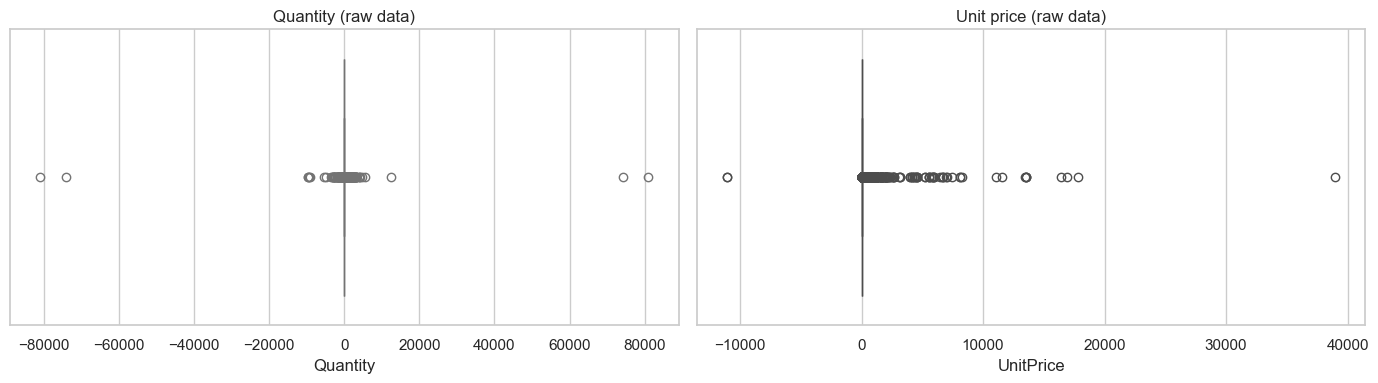

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df["Quantity"], ax=axes[0], color="lightgreen")
axes[0].set_title("Quantity (raw data)")

sns.boxplot(x=df["UnitPrice"], ax=axes[1], color="orange")
axes[1].set_title("Unit price (raw data)")

plt.tight_layout()
plt.show()

df.loc[df["Quantity"].abs().nlargest(4).index,
       ["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]]

### 1.4 Data quality summary

| Issue | Rows affected | What it means for the business |
|---|---|---|
| Missing CustomerID | 135,080 (24.9%) | Sales can't be linked to a customer, so these are useful for revenue but not for customer analysis |
| Missing Description | 1,454 (0.27%) | Product unknown, and most also have a price of 0 |
| Exact duplicates | 5,268 | Likely system errors that would double-count sales |
| Cancelled invoices ("C") | 9,288 | Orders reversed after being placed, so they're not real sales |
| Quantity ≤ 0 | 10,624 | Mostly cancellations, plus stock write-offs (e.g. "damaged", "thrown away") |
| UnitPrice ≤ 0 | 2,517 | Free items or adjustments, with no revenue |
| Non-product codes | ~2,800 | Postage, fees and manual adjustments, which aren't product sales |
| Extreme outliers | A few rows | Very large orders (e.g. 80,995 units) that were immediately cancelled |

**Limitations:** the data covers just over one year (Dec 2010 to Dec 2011), so seasonal patterns are based on a single year. December 2011 is only partly included (up to 9 December). Most transactions come from the United Kingdom, so the other countries have much less data.